
K = 100
Accuracy : 0.8164
Precision: 0.8227761557199162
Recall   : 0.8164
F1 Score : 0.8163418823733144

K = 200
Accuracy : 0.8011
Precision: 0.8086230255034115
Recall   : 0.8011
F1 Score : 0.8009033811334398

K = 1000
Accuracy : 0.7571
Precision: 0.7697892177221218
Recall   : 0.7571
F1 Score : 0.7578036920511965

Results Summary
      K  Accuracy  Precision  Recall  F1 Score
0   100    0.8164   0.822776  0.8164  0.816342
1   200    0.8011   0.808623  0.8011  0.800903
2  1000    0.7571   0.769789  0.7571  0.757804


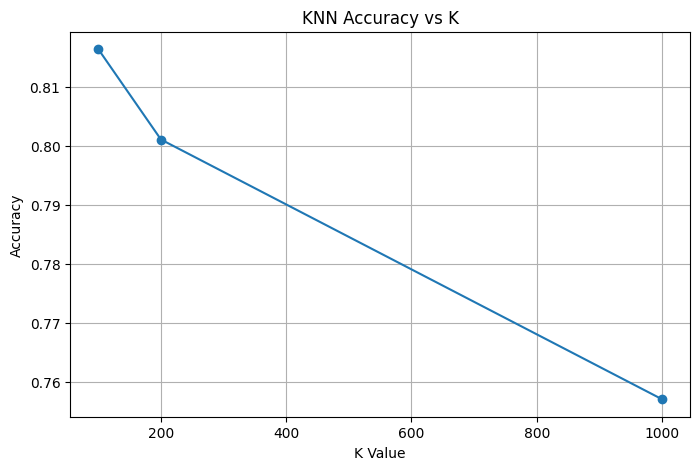

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import fashion_mnist
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score


# Load Fashion MNIST Dataset
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()


# Preprocessing

# Normalize pixel values
X_train = X_train / 255.0
X_test = X_test / 255.0


# Flatten images
X_train = X_train.reshape(len(X_train), -1)
X_test = X_test.reshape(len(X_test), -1)


# Experiment with Different K Values
k_values = [100,200,1000]
results = []

for k in k_values:

    knn = KNeighborsClassifier(n_neighbors=k)

    knn.fit(X_train, y_train)

    y_pred = knn.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test,
        y_pred,
        average='weighted'
    )

    recall = recall_score(
        y_test,
        y_pred,
        average='weighted'
    )

    f1 = f1_score(
        y_test,
        y_pred,
        average='weighted'
    )

    results.append(
        [k, accuracy, precision, recall, f1]
    )

    print(f"\nK = {k}")
    print("Accuracy :", accuracy)
    print("Precision:", precision)
    print("Recall   :", recall)
    print("F1 Score :", f1)


# Results Table
results_df = pd.DataFrame(
    results,
    columns=[
        'K',
        'Accuracy',
        'Precision',
        'Recall',
        'F1 Score'
    ]
)

print("\nResults Summary")
print(results_df)


# Accuracy Plot
plt.figure(figsize=(8, 5))

plt.plot(
    results_df['K'],
    results_df['Accuracy'],
    marker='o'
)

plt.xlabel("K Value")
plt.ylabel("Accuracy")
plt.title("KNN Accuracy vs K")
plt.grid(True)
plt.show()